In [ ]:
# Persiapan lingkungan: tambahan untuk notebook.
import sys
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyBboxPatch, FancyArrowPatch

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
})
print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__)
print('Matplotlib:', matplotlib.__version__)
print('Contoh dapat dijalankan dengan CPU tanpa mengunduh dataset.')

Python: 3.13.16
NumPy: 2.1.3
Matplotlib: 3.10.0
Contoh dapat dijalankan dengan CPU tanpa mengunduh dataset.


## 2. Ringkasan Chapter 7

Setelah membangun jaringan dan backpropagation pada bab sebelumnya, buku mengajak pembaca menyederhanakan cara berpikir. Detail setiap neuron tetap berguna, tetapi jaringan yang lebih besar lebih mudah dipahami melalui kelompok operasi. Istilah **correlation summarization** merangkum bahwa model berusaha mempelajari hubungan antara input dan output, termasuk melalui representasi intermediate.

Secara lokal, satu matriks bobot menghubungkan activation sebelum dan sesudahnya. Secara global, informasi dari loss di output diteruskan menuju lapisan sebelumnya melalui backpropagation. Ringkasan ini membantu memahami tujuan pembaruan bobot tanpa perlu membayangkan semua koneksi sekaligus.

Diagram lalu disederhanakan menjadi vektor dan matriks. Bila lapisan input mempunyai tiga unit dan hidden layer empat unit, matriks penghubung memiliki shape `(3, 4)` dengan konvensi row vector. Hidden layer empat unit yang terhubung ke satu output memerlukan matriks `(4, 1)`. Dengan mengetahui jumlah unit, bentuk matriks dapat diturunkan.

Diagram yang sama dapat ditulis sebagai rumus dan Python: hidden activation berasal dari ReLU atas perkalian input dengan matriks pertama, kemudian dikalikan matriks kedua. Berbagai representasi tersebut saling melengkapi. Bab ditutup dengan gagasan bahwa arsitektur mengatur aliran sinyal, sehingga pilihan arsitektur perlu mempertimbangkan pola data, noise, dan generalisasi.

**Rujukan:** Trask (2019), hlm. 133-143.

## 3. Peta subbab dan cakupan

| Subbab buku | Halaman cetak | Isi notebook |
| --- | --- | --- |
| It's time to simplify | 134 | Abstraksi konsep dan hubungan dengan bab sebelumnya |
| Correlation summarization | 135 | Ringkasan umum, local, dan global |
| The previously overcomplicated visualization | 136 | Keterbatasan diagram setiap koneksi |
| The simplified visualization | 137 | Neuron, vektor, matriks, dan shape |
| Simplifying even further | 138 | Inferensi bentuk bobot serta arti arsitektur |
| Let's see this network predict | 139 | Aliran input, hidden ReLU, dan skor output |
| Visualizing using letters instead of pictures | 140 | Notasi lapisan dan matriks bobot |
| Linking the variables | 141 | Rumus perkalian serta komposisi fungsi |
| Everything side by side | 142 | Reproduksi listing satu baris dan pemetaan diagram-rumus-kode |
| The importance of visualization tools | 143 | Debugging, signal, noise, dan generalisasi |

Contoh bobot, grafik, pemrosesan batch, pemeriksaan shape, dan satu update gradien merupakan tambahan pembelajaran. Sumber dan tujuan setiap tambahan dijelaskan pada bagian terkait.

## 4. It's time to simplify: menggunakan abstraksi

Pada Chapter 3-6, forward propagation, loss, gradien, dan pembaruan bobot dibahas melalui operasi kecil. Saat jaringan membesar, mengingat semua angka sekaligus akan menyulitkan pemahaman. Abstraksi membantu mengelompokkan detail menjadi konsep yang dapat digunakan kembali.

Contohnya, satu matriks bobot mewakili banyak koneksi antar neuron. Menyebut operasi `X @ W` berarti melakukan seluruh weighted sum yang dibutuhkan untuk menghasilkan lapisan berikutnya. Informasi penting yang dipertahankan adalah fungsi operasi, arah aliran, shape, dan activation yang digunakan.

Cara belajar yang disarankan buku ialah membangun kembali contoh berdasarkan konsep. Jika memahami mengapa input dikalikan matriks, mengapa ReLU diterapkan, dan bagaimana output terbentuk, mahasiswa dapat menulis ulang kode dengan nama variabel berbeda tanpa mengubah maknanya.

**Rujukan:** Trask (2019), hlm. 134.

## 5. Correlation summarization: umum, local, dan global

**Ringkasan umum.** Jaringan mempelajari hubungan antara input dan target. Hubungan itu dapat langsung atau terbentuk melalui hidden representation. Dalam buku, kata *correlation* digunakan sebagai intuisi luas untuk pola yang membantu prediksi.

**Local correlation summarization.** Sebuah matriks bobot menerima activation dari lapisan sebelumnya dan mengubahnya menjadi sinyal bagi lapisan berikutnya. Pembaruan parameternya bergantung pada activation input dan informasi turunan loss yang sampai ke lapisan tersebut.

**Global correlation summarization.** Kesalahan di output memengaruhi pembaruan lapisan sebelumnya. Backpropagation memakai aturan rantai untuk meneruskan sensitivitas loss melalui matriks bobot dan fungsi activation. Hidden layer tidak memerlukan label tersendiri untuk setiap neuronnya; sinyal pembelajarannya diperoleh dari loss akhir.

Untuk satu sampel, tuliskan $h=\operatorname{ReLU}(xW_0)$ dan $\hat y=hW_1$. Bila $d_2=\partial L/\partial\hat y$, maka:

$$
\frac{\partial L}{\partial W_1}=h^T d_2,
\qquad
d_1=(d_2W_1^T)\odot\mathbf{1}_{xW_0>0},
\qquad
\frac{\partial L}{\partial W_0}=x^T d_1.
$$

Perkalian dengan bobot dan mask ReLU menentukan arah serta besarnya sinyal. Ungkapan buku tentang lapisan yang meminta sinyal lebih tinggi/rendah adalah metafora; tanda bobot dapat membalik arah sensitivitas dan ReLU dapat menghentikannya.

**Batas interpretasi:** model tidak menghitung koefisien korelasi Pearson dalam setiap update. Algoritma mengoptimalkan loss yang ditetapkan. Ketergantungan nonlinear, seperti XOR, dapat berguna walaupun korelasi marginal suatu feature dengan target nol. Pola prediktif juga belum membuktikan hubungan sebab-akibat atau kemampuan generalisasi.

**Rujukan:** Trask (2019), hlm. 135; rumus merupakan pendalaman yang menghubungkan kembali backpropagation Chapter 6, hlm. 130.

## 6. Dari setiap koneksi menuju vektor dan matriks

Diagram fully connected menggambar setiap neuron serta garis yang menghubungkannya. Pada jaringan 3-4-1, terdapat 12 koneksi input-hidden dan 4 koneksi hidden-output. Bila hidden layer memiliki ratusan unit, garis-garis itu semakin sulit dibaca.

Buku mengganti kumpulan neuron dengan vektor dan kumpulan koneksi dengan matriks. Abstraksi ini tetap menunjukkan bagian jaringan yang diperlukan untuk melakukan perhitungan.

| Komponen | Arti | Contoh shape |
| --- | --- | --- |
| Scalar | Satu nilai | Satu skor atau satu bobot |
| Vektor lapisan satu sampel | Kumpulan nilai activation | `(1, 3)` atau `(1, 4)` |
| Matriks bobot | Kumpulan parameter antar lapisan | `(3, 4)` atau `(4, 1)` |
| Matriks activation beberapa sampel | Satu baris untuk setiap sampel | `(N, 3)` atau `(N, 4)` |

Secara matematis, vektor bisa dipandang sebagai matriks satu baris atau satu kolom. Dalam NumPy, array satu dimensi `(3,)` berbeda dari array dua dimensi `(1, 3)`. Notebook memakai **row vector dua dimensi** untuk memperjelas shape dan transpose.

**Rujukan:** Trask (2019), hlm. 136-137.

## 7. Menentukan shape dari jumlah unit

Jika activation input berukuran `(N, d_in)` dan lapisan berikutnya mempunyai `d_out` unit, bobotnya berukuran `(d_in, d_out)`:

$$
(N\times d_{\mathrm{in}})(d_{\mathrm{in}}\times d_{\mathrm{out}})
=N\times d_{\mathrm{out}}.
$$

Dimensi dalam harus sama. Setiap kolom bobot menyimpan koefisien bagi satu neuron pada lapisan tujuan.

| Nama buku | Notasi | Shape satu sampel | Peran |
| --- | --- | --- | --- |
| `layer_0` | $\ell_0$ | `(1, 3)` | Input |
| `weights_0_1` | $W_0$ | `(3, 4)` | Input ke hidden |
| `layer_1` | $\ell_1$ | `(1, 4)` | Activation hidden |
| `weights_1_2` | $W_1$ | `(4, 1)` | Hidden ke output |
| `layer_2` | $\ell_2$ | `(1, 1)` | Prediksi |

Urutan dimensi bergantung pada konvensi representasi. Jika memakai column vector, penulisan perkaliannya berubah. Pada bab ini, seluruh formula dan kode mengikuti row vector pada buku.

**Rujukan:** Trask (2019), hlm. 137-138.

In [ ]:
# Tambahan: menurunkan bentuk matriks dari arsitektur.
widths = [3, 4, 1]
weight_shapes = list(zip(widths[:-1], widths[1:]))
parameter_count = sum(rows * columns for rows, columns in weight_shapes)

for index, shape in enumerate(weight_shapes):
    print(f'W{index}: {shape}, jumlah bobot = {shape[0] * shape[1]}')
print('Jumlah bobot tanpa variabel bias terpisah:', parameter_count)
assert weight_shapes == [(3, 4), (4, 1)]
assert parameter_count == 16

W0: (3, 4), jumlah bobot = 12
W1: (4, 1), jumlah bobot = 4
Jumlah bobot tanpa variabel bias terpisah: 16


Model 3-4-1 ini memiliki **16 bobot**, dengan dua matriks parameter. Hidden width `4` merupakan pilihan arsitektur; width tersebut menentukan shape kedua matriks yang berdekatan. Banyak unit atau jumlah bobot saja belum menjelaskan seluruh arsitektur: jenis koneksi, posisi activation, dan urutan operasi juga perlu diketahui.

Kode buku yang dipakai tidak menyediakan variabel bias terpisah. Jika feature ketiga selalu `1`, baris ketiga $W_0$ dapat berfungsi sebagai offset untuk hidden unit. Bila bias eksplisit ditambahkan, bentuk umum menjadi $h=\operatorname{ReLU}(xW_0+b_0)$ dan $\hat y=hW_1+b_1$. Itu merupakan perluasan model, sehingga jumlah parameter dan rumus perlu disesuaikan.

ReLU tidak mengubah shape, tetapi mengubah nilai dan sifat fungsi. Karena itu, diagram yang hanya menuliskan jumlah unit tanpa activation masih belum lengkap untuk merekonstruksi perhitungan.

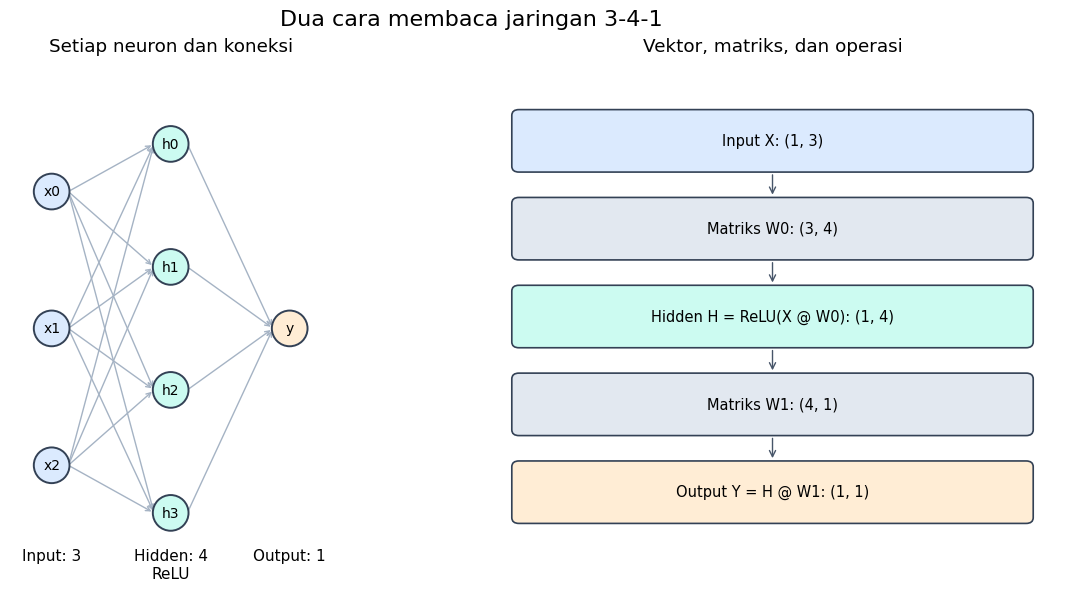

In [ ]:
# Visualisasi tambahan: dua representasi dari arsitektur yang sama.
fig, axes = plt.subplots(1, 2, figsize=(12, 5.8), layout='constrained')
ax = axes[0]
ax.set_xlim(-0.35, 2.35)
ax.set_ylim(-1.95, 2.15)
ax.set_aspect('equal')
ax.axis('off')
input_y = np.linspace(1.15, -1.15, 3)
hidden_y = np.linspace(1.55, -1.55, 4)

for left_y in input_y:
    for right_y in hidden_y:
        ax.add_patch(FancyArrowPatch((0.14, left_y), (0.86, right_y),
                                    arrowstyle='->', mutation_scale=8,
                                    color='#a5b3c4', linewidth=1.0, zorder=1))
for left_y in hidden_y:
    ax.add_patch(FancyArrowPatch((1.14, left_y), (1.86, 0),
                                arrowstyle='->', mutation_scale=8,
                                color='#a5b3c4', linewidth=1.0, zorder=1))
for x, ys, prefix, color in [
    (0, input_y, 'x', '#dbeafe'),
    (1, hidden_y, 'h', '#ccfbf1'),
    (2, [0], 'y', '#ffedd5'),
]:
    for index, y in enumerate(ys):
        ax.add_patch(Circle((x, y), 0.15, facecolor=color,
                            edgecolor='#334155', linewidth=1.4, zorder=2))
        label = f'{prefix}{index}' if prefix != 'y' else 'y'
        ax.text(x, y, label, ha='center', va='center', fontsize=10, zorder=3)
for x, text in [(0, 'Input: 3'), (1, 'Hidden: 4\nReLU'), (2, 'Output: 1')]:
    ax.text(x, -1.85, text, ha='center', va='top', fontsize=11)
ax.set_title('Setiap neuron dan koneksi', pad=15)

ax = axes[1]
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis('off')
blocks = [
    (0.86, 'Input X: (1, 3)', '#dbeafe'),
    (0.68, 'Matriks W0: (3, 4)', '#e2e8f0'),
    (0.50, 'Hidden H = ReLU(X @ W0): (1, 4)', '#ccfbf1'),
    (0.32, 'Matriks W1: (4, 1)', '#e2e8f0'),
    (0.14, 'Output Y = H @ W1: (1, 1)', '#ffedd5'),
]
for index, (y, label, color) in enumerate(blocks):
    ax.add_patch(FancyBboxPatch((0.07, y - 0.052), 0.86, 0.104,
                              boxstyle='round,pad=0.012', facecolor=color,
                              edgecolor='#334155', linewidth=1.2))
    ax.text(0.5, y, label, ha='center', va='center', fontsize=10.5)
    if index < len(blocks) - 1:
        next_y = blocks[index + 1][0]
        ax.annotate('', xy=(0.5, next_y + 0.064), xytext=(0.5, y - 0.064),
                    arrowprops={'arrowstyle': '->', 'color': '#475569'})
ax.set_title('Vektor, matriks, dan operasi', pad=15)
fig.suptitle('Dua cara membaca jaringan 3-4-1', fontsize=16)
plt.show()

Diagram kiri berguna untuk melihat semua koneksi. Diagram kanan mengelompokkan koneksi menjadi matriks, sambil mempertahankan ukuran dan operasi. Kedua diagram menjelaskan jaringan yang sama.

**Catatan gambar buku:** ilustrasi skematis halaman 142 menampilkan tiga hidden unit, sedangkan contoh ukuran pada halaman 137-139 memakai empat. Rumus umum berlaku untuk kedua ukuran jika shape bobot disesuaikan. Contoh numerik notebook mengikuti ukuran **3-4-1** pada halaman 137-139.

## 8. Let's see this network predict: menyiapkan contoh numerik

Halaman 139 memperlihatkan tiga tahap: menetapkan input, menghitung hidden activation dengan ReLU, lalu menghasilkan output. Angka yang diberikan adalah:

$$
x=[1,0,1],\qquad h=[0.5,0.2,0,0.9],\qquad\hat y=0.9.
$$

Matriks berikut merupakan **konstruksi tambahan**, bukan bobot training yang disediakan buku:

$$
W_0=\begin{bmatrix}
0.3&0.1&-0.4&0.5\\
0.2&-0.3&0.6&-0.1\\
0.2&0.1&-0.3&0.4
\end{bmatrix},\qquad
W_1=\begin{bmatrix}0.6\\0.3\\-0.4\\0.6\end{bmatrix}.
$$

Dengan bobot ini, preactivation hidden menjadi `[0.5, 0.2, -0.7, 0.9]`. Nilai `-0.7` dipilih sendiri untuk menunjukkan pemotongan oleh ReLU; buku hanya menyatakan bahwa nilai tersebut negatif. Banyak matriks lain juga dapat menghasilkan activation dan output yang sama pada satu input.

**Rujukan:** Trask (2019), hlm. 139.

In [ ]:
# Bobot buatan untuk mencocokkan angka ilustrasi halaman 139.
layer_0 = np.array([[1.0, 0.0, 1.0]])
weights_0_1 = np.array([
    [0.3,  0.1, -0.4,  0.5],
    [0.2, -0.3,  0.6, -0.1],
    [0.2,  0.1, -0.3,  0.4],
])
weights_1_2 = np.array([[0.6], [0.3], [-0.4], [0.6]])

def relu(values):
    return np.maximum(0.0, values)

print('layer_0:', layer_0, 'shape:', layer_0.shape)
print('weights_0_1:')
print(weights_0_1)
print('weights_1_2:')
print(weights_1_2)

layer_0: [[1. 0. 1.]] shape: (1, 3)
weights_0_1:
[[ 0.3  0.1 -0.4  0.5]
 [ 0.2 -0.3  0.6 -0.1]
 [ 0.2  0.1 -0.3  0.4]]
weights_1_2:
[[ 0.6]
 [ 0.3]
 [-0.4]
 [ 0.6]]


## 9. Reproduksi listing inti: Everything side by side

Baris pertama sel berikut mereproduksi listing pada halaman 142. Fungsi ReLU dan variabelnya sudah disiapkan pada sel sebelumnya. Baris pencetakan merupakan tambahan untuk menampilkan hasil.

Urutannya adalah perkalian `layer_0` dengan `weights_0_1`, penerapan ReLU, lalu perkalian dengan `weights_1_2`. Hasil akhirnya memiliki shape `(1, 1)`.

**Rujukan:** Trask (2019), hlm. 142.

In [ ]:
layer_2 = relu(layer_0.dot(weights_0_1)).dot(weights_1_2)

# Tambahan logging; baris di atas adalah listing inti buku.
print('Prediksi:', layer_2)
print('Shape output:', layer_2.shape)

Prediksi: [[0.9]]
Shape output: (1, 1)


## 10. Membaca perhitungan tahap demi tahap

Setiap hidden unit menjumlahkan kontribusi seluruh input memakai satu kolom $W_0$:

$$
z_j=\sum_{i=0}^{2}x_i(W_0)_{ij},\qquad
h_j=\max(0,z_j),\qquad
\hat y=\sum_{j=0}^{3}h_j(W_1)_{j0}.
$$

Perkalian `(1, 3)` dengan `(3, 4)` menghasilkan empat weighted sum. ReLU mengubah nilai negatif menjadi nol tanpa mengubah jumlah komponen. Perkalian berikutnya menggabungkan empat activation menjadi satu skor.

| Hidden unit | Weighted sum sebelum ReLU | Setelah ReLU |
| --- | --- | --- |
| h0 | $1(0.3)+0(0.2)+1(0.2)=0.5$ | 0.5 |
| h1 | $1(0.1)+0(-0.3)+1(0.1)=0.2$ | 0.2 |
| h2 | $1(-0.4)+0(0.6)+1(-0.3)=-0.7$ | 0 |
| h3 | $1(0.5)+0(-0.1)+1(0.4)=0.9$ | 0.9 |

**Rujukan:** Trask (2019), hlm. 139; rincian bobot adalah contoh tambahan notebook.

In [ ]:
# Tambahan: memecah listing satu baris menjadi tiga tahap.
preactivation = layer_0.dot(weights_0_1)
layer_1 = relu(preactivation)
prediction_staged = layer_1.dot(weights_1_2)

input_contributions = layer_0.reshape(3, 1) * weights_0_1
output_contributions = layer_1.ravel() * weights_1_2.ravel()
print('Kontribusi tiap input ke empat hidden unit:')
print(input_contributions)
print('Preactivation:', preactivation)
print('Activation ReLU:', layer_1)
print('Kontribusi hidden ke output:', output_contributions)
print('Jumlah kontribusi output:', output_contributions.sum())

np.testing.assert_allclose(input_contributions.sum(axis=0), preactivation[0])
np.testing.assert_allclose(layer_1, [[0.5, 0.2, 0.0, 0.9]])
np.testing.assert_allclose(prediction_staged, layer_2)
np.testing.assert_allclose(layer_2, [[0.9]])

Kontribusi tiap input ke empat hidden unit:
[[ 0.3  0.1 -0.4  0.5]
 [ 0.  -0.   0.  -0. ]
 [ 0.2  0.1 -0.3  0.4]]
Preactivation: [[ 0.5  0.2 -0.7  0.9]]
Activation ReLU: [[0.5 0.2 0.  0.9]]
Kontribusi hidden ke output: [ 0.3   0.06 -0.    0.54]
Jumlah kontribusi output: 0.9


Output contoh diperoleh dari $0.5(0.6)+0.2(0.3)+0(-0.4)+0.9(0.6)=0.9$. Input tengah tidak menyumbang nilai pada sampel ini karena nilainya nol; bobot pada baris tengah tetap dapat digunakan oleh sampel lain.

**Weighted sum dan weighted average:** halaman 139 menyebut langkah akhir sebagai weighted average, tetapi operasi `dot` menghitung **weighted sum**. Tidak ada pembagian dengan jumlah bobot atau syarat bobot membentuk rata-rata. Karena itu, nilai output tidak otomatis dibatasi antara 0 dan 1.

Skor `0.9` juga belum merupakan probabilitas yang terkalibrasi. Contoh ini hanya memakai output linear. Kesamaan dengan angka diagram tidak membuktikan bahwa bobot tersebut unik atau berhasil mempelajari seluruh dataset.

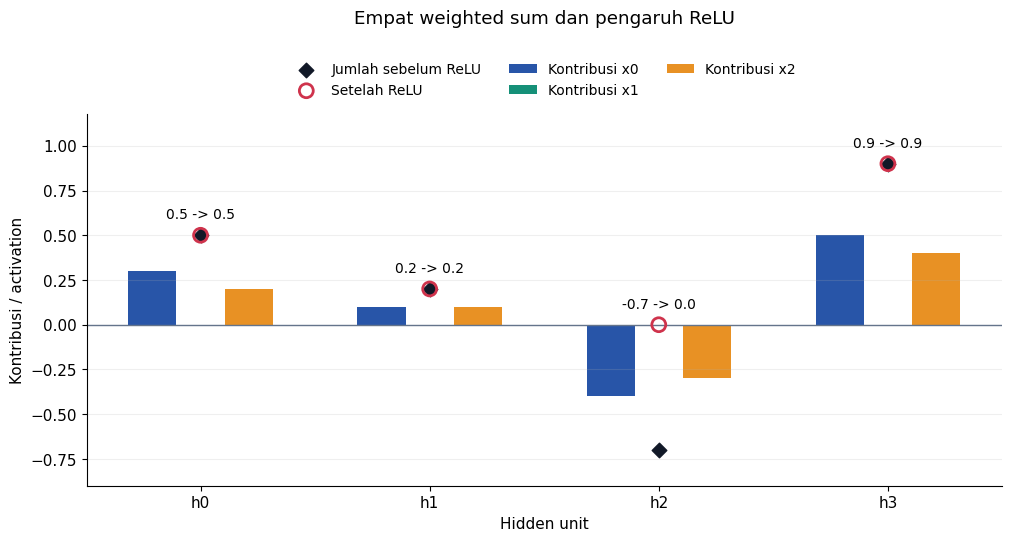

In [ ]:
# Visualisasi tambahan: kontribusi input, weighted sum, dan ReLU.
fig, ax = plt.subplots(figsize=(10, 5.3), layout='constrained')
positions = np.arange(layer_1.shape[1])
bar_width = 0.21
colors = ['#2855a8', '#159078', '#e89124']
for index in range(layer_0.shape[1]):
    ax.bar(positions + (index - 1) * bar_width,
           input_contributions[index], width=bar_width,
           color=colors[index], label=f'Kontribusi x{index}')
ax.scatter(positions, preactivation[0], marker='D', s=55,
           color='#111827', label='Jumlah sebelum ReLU', zorder=4)
ax.scatter(positions, layer_1[0], marker='o', s=100, facecolors='none',
           edgecolors='#cf334c', linewidths=2, label='Setelah ReLU', zorder=5)
for index, (raw, activated) in enumerate(zip(preactivation[0], layer_1[0])):
    ax.annotate(f'{raw:.1f} -> {activated:.1f}',
                xy=(index, max(raw, activated)), xytext=(0, 12),
                textcoords='offset points', ha='center', fontsize=10)
ax.axhline(0, color='#64748b', linewidth=1)
ax.set_xticks(positions, ['h0', 'h1', 'h2', 'h3'])
ax.set_ylim(-0.9, 1.18)
ax.set_xlabel('Hidden unit')
ax.set_ylabel('Kontribusi / activation')
ax.set_title('Empat weighted sum dan pengaruh ReLU', pad=65)
ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.01),
          ncol=3, frameon=False, fontsize=10)
ax.grid(axis='y', alpha=0.2)
plt.show()

Pada h2, kontribusi input berjumlah `-0.7`. ReLU mengubahnya menjadi `0`, sehingga neuron tersebut tidak memberi kontribusi ke output untuk input ini. Hidden unit lain mempertahankan nilai positifnya. Grafik menunjukkan operasi yang sama dengan kode dan tabel sebelumnya.

Nilai activation nol bersifat bergantung pada input. H2 dapat aktif pada input berbeda; misalnya bobot input tengahnya positif. Jadi, activation nol pada satu sampel tidak berarti neuron tersebut selalu tidak berguna.

## 11. Visualizing using letters instead of pictures

Notasi membantu menulis diagram secara ringkas. Buku memakai huruf kapital untuk matriks bobot dan huruf kecil untuk vektor lapisan. Indeks membedakan beberapa lapisan dan matriks. Notebook menulis huruf lapisan sebagai $\ell$ agar tidak tertukar dengan angka `1`.

| Diagram atau kode | Notasi | Makna |
| --- | --- | --- |
| Vektor input `layer_0` | $\ell_0$ | Nilai yang masuk ke jaringan |
| Matriks `weights_0_1` | $W_0$ | Bobot input-hidden |
| Vektor hidden `layer_1` | $\ell_1$ | Activation setelah ReLU |
| Matriks `weights_1_2` | $W_1$ | Bobot hidden-output |
| Vektor output `layer_2` | $\ell_2$ | Prediksi jaringan |

Pemilihan huruf merupakan konvensi, bukan aturan wajib Python. Huruf yang berbeda dapat mewakili operasi yang sama selama definisi dan shape-nya konsisten. Sebaliknya, memakai nama yang sama tidak menjamin operasi benar jika bentuk array tidak sesuai.

**Rujukan:** Trask (2019), hlm. 140.

## 12. Linking the variables: menghubungkan operasi

Menulis dua simbol berdekatan, seperti $\ell_0W_0$, menunjukkan perkalian matriks dengan urutan tersebut. ReLU diterapkan pada setiap komponen hasil perkalian. Hubungan antar lapisan adalah:

$$
\ell_1=\operatorname{ReLU}(\ell_0W_0),\qquad
\ell_2=\ell_1W_1.
$$

Substitusi rumus hidden layer ke output memberikan satu ekspresi:

$$
\boxed{\ell_2=\operatorname{ReLU}(\ell_0W_0)W_1}.
$$

Fungsi yang ditulis paling dalam dihitung lebih dahulu. Ekspresi ringkas ini tetap menyimpan urutan operasi dan posisi ReLU. Rumus juga mengasumsikan dimensi dalam setiap perkalian sesuai.

Dalam NumPy, `@` pada array dua dimensi melakukan perkalian matriks yang sama dengan `.dot()` pada contoh ini. Operator `*` melakukan perkalian elementwise, sehingga tidak menggantikan perkalian matriks pada listing.

**Rujukan:** Trask (2019), hlm. 141-142.

In [ ]:
# Tambahan: penulisan ekuivalen dengan operator @.
prediction_at = relu(layer_0 @ weights_0_1) @ weights_1_2
print('Hasil .dot():', layer_2)
print('Hasil @     :', prediction_at)
np.testing.assert_allclose(prediction_at, layer_2)
print('Kedua penulisan menghasilkan nilai dan shape yang sama.')

Hasil .dot(): [[0.9]]
Hasil @     : [[0.9]]
Kedua penulisan menghasilkan nilai dan shape yang sama.


## 13. Mengapa posisi ReLU perlu dipertahankan?

Perkalian matriks bersifat asosiatif ketika shape sesuai: $(xW_0)W_1=x(W_0W_1)$. Namun, menyisipkan fungsi nonlinear mengubah hubungan tersebut. Secara umum:

$$
\operatorname{ReLU}(xW_0)W_1
\ne\operatorname{ReLU}\bigl(x(W_0W_1)\bigr).
$$

Pada contoh kita, ReLU di hidden layer memotong nilai `-0.7` sebelum nilai itu dikalikan bobot output `-0.4`. Jika ReLU di hidden dihilangkan, kedua bilangan negatif tersebut memberikan kontribusi positif `0.28`. Hasil berubah dari `0.9` menjadi `1.18`.

Karena itu, shape yang sesuai merupakan syarat perhitungan, tetapi belum menjamin fungsi yang dihitung sesuai arsitektur. Urutan operasi dan activation juga harus benar. Ini merupakan pendalaman formula halaman 141 serta keterbatasan lapisan linear pada Chapter 6.

In [ ]:
# Tambahan: perubahan fungsi ketika ReLU dipindah atau dihilangkan.
linear_chain = (layer_0 @ weights_0_1) @ weights_1_2
linear_collapsed = layer_0 @ (weights_0_1 @ weights_1_2)
relu_at_output = relu(linear_collapsed)

print('ReLU pada hidden, sesuai buku :', layer_2)
print('Tanpa ReLU di hidden         :', linear_chain)
print('ReLU dipindah ke output      :', relu_at_output)
np.testing.assert_allclose(linear_chain, linear_collapsed)
np.testing.assert_allclose(linear_chain, [[1.18]])
assert not np.allclose(relu_at_output, layer_2)

ReLU pada hidden, sesuai buku : [[0.9]]
Tanpa ReLU di hidden         : [[1.18]]
ReLU dipindah ke output      : [[1.18]]


## 14. Row vector dua dimensi dan array satu dimensi

Array NumPy `[1, 0, 1]` mempunyai shape `(3,)`, bukan `(1, 3)`. Menuliskannya dengan kurung siku tambahan menghasilkan satu baris dengan shape `(1, 3)`.

| Bentuk input | Shape hidden | Shape output | Makna |
| --- | --- | --- | --- |
| `(3,)` | `(4,)` | `(1,)` | Satu sampel tanpa sumbu batch eksplisit |
| `(1, 3)` | `(1, 4)` | `(1, 1)` | Satu sampel dengan sumbu batch |
| `(N, 3)` | `(N, 4)` | `(N, 1)` | N sampel dalam satu matriks |

Nilai prediksi bisa sama, tetapi bentuk array berbeda. Pada array satu dimensi, `.T` tidak mengubah shape. Untuk membuat column vector, gunakan reshape seperti `.reshape(3, 1)` atau transpose row vector `(1, 3)`.

Pendalaman ini membantu menerjemahkan bentuk vektor pada diagram halaman 137 ke objek NumPy yang benar.

In [ ]:
# Tambahan: membandingkan bentuk array satu dan dua dimensi.
input_flat = layer_0.ravel()
hidden_flat = relu(input_flat @ weights_0_1)
output_flat = hidden_flat @ weights_1_2

print('Input 1D / .T:', input_flat.shape, input_flat.T.shape)
print('Input 2D / .T:', layer_0.shape, layer_0.T.shape)
print('Hidden 1D:', hidden_flat.shape, 'Output 1D:', output_flat.shape)
print('Hidden 2D:', layer_1.shape, 'Output 2D:', layer_2.shape)
np.testing.assert_allclose(output_flat.reshape(1, 1), layer_2)
assert input_flat.T.shape == (3,)
assert layer_0.T.shape == (3, 1)

Input 1D / .T: (3,) (3,)
Input 2D / .T: (1, 3) (3, 1)
Hidden 1D: (4,) Output 1D: (1,)
Hidden 2D: (1, 4) Output 2D: (1, 1)


## 15. Memperluas gambar satu sampel menjadi beberapa sampel

Untuk $N$ sampel, setiap baris $X$ berisi satu input. Bobot tetap dipakai bersama pada seluruh baris:

$$
X\in\mathbb R^{N\times3},\quad
H=\operatorname{ReLU}(XW_0)\in\mathbb R^{N\times4},\quad
\hat Y=HW_1\in\mathbb R^{N\times1}.
$$

Jumlah sampel mengubah shape activation, sementara shape matriks bobot tetap. Perkalian dilakukan pada setiap baris sehingga prediksi satu sampel tidak tercampur dengan sampel lainnya.

Sel berikut memakai input diagram ditambah tiga pola kecil untuk menguji perluasan ini. **Bobot masih merupakan bobot buatan**, sehingga skor pada pola tambahan tidak diklaim sebagai hasil pembelajaran atau akurasi klasifikasi. Pemrosesan batch di sini hanya forward propagation, tanpa update mini-batch.

In [ ]:
# Tambahan: fungsi forward dengan pemeriksaan shape yang jelas.
def forward(inputs, w0, w1):
    inputs = np.asarray(inputs, dtype=float)
    if inputs.ndim != 2 or w0.ndim != 2 or w1.ndim != 2:
        raise ValueError('Input dan bobot harus berupa array dua dimensi.')
    if inputs.shape[1] != w0.shape[0]:
        raise ValueError('Jumlah feature input harus sama dengan jumlah baris W0.')
    if w0.shape[1] != w1.shape[0]:
        raise ValueError('Jumlah kolom W0 harus sama dengan jumlah baris W1.')
    return relu(inputs @ w0) @ w1

batch_inputs = np.array([
    [1.0, 0.0, 1.0],
    [0.0, 1.0, 1.0],
    [0.0, 0.0, 1.0],
    [1.0, 1.0, 1.0],
])
batch_predictions = forward(batch_inputs, weights_0_1, weights_1_2)
individual_predictions = np.vstack([
    forward(batch_inputs[index:index+1], weights_0_1, weights_1_2)
    for index in range(len(batch_inputs))
])
print('Shape input batch:', batch_inputs.shape)
print('Shape hidden batch:', relu(batch_inputs @ weights_0_1).shape)
print('Shape output batch:', batch_predictions.shape)
print('Input -> skor')
for inputs, score in zip(batch_inputs, batch_predictions[:, 0]):
    print(f'{inputs.astype(int).tolist()} -> {score:.6f}')
np.testing.assert_allclose(batch_predictions, individual_predictions)
assert batch_predictions.shape == (4, 1)

Shape input batch: (4, 3)
Shape hidden batch: (4, 4)
Shape output batch: (4, 1)
Input -> skor
[1, 0, 1] -> 0.900000
[0, 1, 1] -> 0.300000
[0, 0, 1] -> 0.390000
[1, 1, 1] -> 0.900000


## 16. Everything side by side: diagram, aljabar, dan Python

| Tahap diagram | Rumus | Python | Shape |
| --- | --- | --- | --- |
| Input dimasukkan | $\ell_0=x$ | `layer_0` | `(1, 3)` |
| Koneksi input-hidden | $z=\ell_0W_0$ | `layer_0.dot(weights_0_1)` | `(1, 4)` |
| Activation hidden | $\ell_1=\operatorname{ReLU}(z)$ | `relu(z)` | `(1, 4)` |
| Koneksi hidden-output | $\ell_2=\ell_1W_1$ | `layer_1.dot(weights_1_2)` | `(1, 1)` |
| Seluruh forward | $\ell_2=\operatorname{ReLU}(\ell_0W_0)W_1$ | `relu(layer_0.dot(weights_0_1)).dot(weights_1_2)` | `(1, 1)` |

Diagram menunjukkan hubungan antar komponen; rumus menunjukkan operasi secara ringkas; kode memberikan implementasi yang dapat dijalankan. Tabel shape membantu memeriksa apakah ketiganya konsisten.

Ekspresi satu baris cocok untuk merangkum forward propagation. Saat melakukan debugging atau backpropagation, memisahkannya menjadi beberapa variabel membantu memeriksa dan menyimpan activation intermediate.

**Rujukan:** Trask (2019), hlm. 142.

## 17. Pendalaman local dan global: melihat sinyal gradien

Bagian ini menghubungkan metafora halaman 135 dengan backpropagation yang sudah dipelajari pada Chapter 6. **Target tambahan dipilih `1.0`** untuk satu input contoh; halaman 139 tidak menetapkan target untuk diagramnya.

Gunakan loss $L=\tfrac12(\hat y-y)^2$, sehingga $d_2=\hat y-y=-0.1$. Konvensi yang dipakai adalah gradien loss dengan update **minus**:

$$
d_1=(d_2W_1^T)\odot\mathbf{1}_{z>0},\qquad
G_1=h^Td_2,\qquad G_0=x^Td_1,\qquad
W_k^{\mathrm{baru}}=W_k-\alpha G_k.
$$

Komunikasi global tampak pada perhitungan $d_1$: loss akhir memengaruhi hidden layer melalui $W_1$ dan mask ReLU. Pembaruan lokal tampak pada outer product activation dengan delta. Gradien setiap matriks mempunyai shape yang sama dengan parameternya.

Semua delta dihitung memakai bobot yang digunakan pada forward yang sama. Jika $W_1$ sudah diperbarui sebelum menghitung $d_1$, gradiennya tidak lagi berasal dari state forward tersebut. Pada titik nol, turunan ReLU tidak terdefinisi secara klasik; contoh memakai konvensi mask `z > 0`, sehingga gradien di nol dipilih nol.

**Rujukan:** Trask (2019), hlm. 135; penurunan dan satu update ini merupakan tambahan berdasarkan Chapter 6, hlm. 130.

In [ ]:
# Tambahan analitis: gradien pada state forward awal.
target_demo = np.array([[1.0]])
loss_before = 0.5 * np.sum((layer_2 - target_demo) ** 2)
output_delta = layer_2 - target_demo
relu_mask = preactivation > 0
hidden_delta = (output_delta @ weights_1_2.T) * relu_mask
gradient_w1 = layer_1.T @ output_delta
gradient_w0 = layer_0.T @ hidden_delta

print('Target tambahan:', target_demo)
print('Delta output:', output_delta)
print('Mask ReLU:', relu_mask.astype(int))
print('Delta hidden:', hidden_delta)
print('Gradien W0:')
print(gradient_w0)
print('Gradien W1:')
print(gradient_w1)
assert gradient_w0.shape == weights_0_1.shape
assert gradient_w1.shape == weights_1_2.shape
np.testing.assert_allclose(hidden_delta, [[-0.06, -0.03, 0.0, -0.06]])
np.testing.assert_allclose(gradient_w0[1], 0.0)
np.testing.assert_allclose(gradient_w0[:, 2], 0.0)
np.testing.assert_allclose(gradient_w1[2], 0.0)

Target tambahan: [[1.]]
Delta output: [[-0.1]]
Mask ReLU: [[1 1 0 1]]
Delta hidden: [[-0.06 -0.03  0.   -0.06]]
Gradien W0:
[[-0.06 -0.03  0.   -0.06]
 [ 0.    0.    0.    0.  ]
 [-0.06 -0.03  0.   -0.06]]
Gradien W1:
[[-0.05]
 [-0.02]
 [ 0.  ]
 [-0.09]]


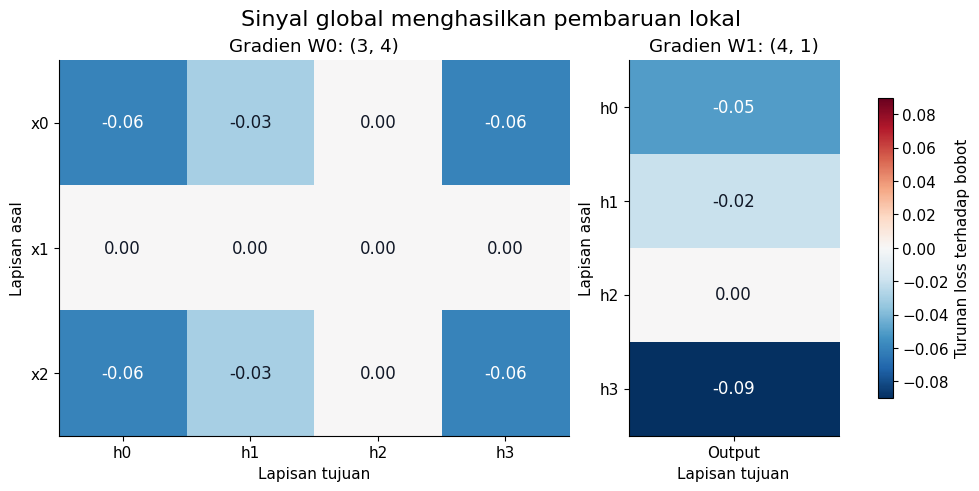

In [ ]:
# Visualisasi tambahan: gradien dua matriks bobot.
fig, axes = plt.subplots(1, 2, figsize=(9.7, 4.8), layout='constrained',
                         gridspec_kw={'width_ratios': [3.4, 1.4]})
bound = max(float(np.abs(gradient_w0).max()), float(np.abs(gradient_w1).max()))
for ax, values, title, xlabels, ylabels in [
    (axes[0], gradient_w0, 'Gradien W0: (3, 4)',
     ['h0', 'h1', 'h2', 'h3'], ['x0', 'x1', 'x2']),
    (axes[1], gradient_w1, 'Gradien W1: (4, 1)',
     ['Output'], ['h0', 'h1', 'h2', 'h3']),
]:
    im = ax.imshow(values, cmap='RdBu_r', vmin=-bound, vmax=bound, aspect='auto')
    ax.set_xticks(range(len(xlabels)), xlabels)
    ax.set_yticks(range(len(ylabels)), ylabels)
    ax.set_title(title)
    ax.set_xlabel('Lapisan tujuan')
    ax.set_ylabel('Lapisan asal')
    for row in range(values.shape[0]):
        for column in range(values.shape[1]):
            value = float(values[row, column])
            display_value = 0.0 if abs(value) < 1e-12 else value
            color = 'white' if abs(value) > bound * 0.55 else '#111827'
            ax.text(column, row, f'{display_value:.2f}', ha='center', va='center',
                    color=color, fontsize=12)
fig.colorbar(im, ax=axes, label='Turunan loss terhadap bobot', shrink=0.8)
fig.suptitle('Sinyal global menghasilkan pembaruan lokal', fontsize=16)
plt.show()

Baris x1 pada gradien $W_0$ nol karena input tengah nol. Kolom h2 pada gradien $W_0$ nol karena ReLU tidak aktif. Gradien koneksi h2-output juga nol karena activation h2 nol. Ini menjelaskan mengapa pembaruan tidak seragam pada seluruh koneksi.

Warna menunjukkan **turunan loss**, bukan nilai bobot atau ukuran korelasi statistik. Gradien negatif berarti update `W -= alpha * gradient` menambah bobot. Delta hidden memiliki arah yang sama pada hidden unit aktif dalam contoh ini karena bobot outputnya positif. Pada bobot output negatif, sensitivitas dapat berbalik arah.

Satu langkah berikut memakai learning rate `0.1` dan salinan bobot. Penurunan loss pada satu sampel ini hanya menunjukkan efek update contoh; tidak memberi bukti generalisasi atau hasil training seluruh dataset.

In [ ]:
# Tambahan: satu update memakai gradien yang sudah dihitung.
alpha_demo = 0.1
weights_0_1_updated = weights_0_1 - alpha_demo * gradient_w0
weights_1_2_updated = weights_1_2 - alpha_demo * gradient_w1
prediction_updated = forward(layer_0, weights_0_1_updated, weights_1_2_updated)
loss_after = 0.5 * np.sum((prediction_updated - target_demo) ** 2)

print(f'Skor sebelum update: {layer_2.item():.6f}')
print(f'Skor setelah update: {prediction_updated.item():.6f}')
print(f'Loss sebelum: {loss_before:.8f}')
print(f'Loss setelah: {loss_after:.8f}')
np.testing.assert_allclose(prediction_updated, [[0.92738]])
assert loss_after < loss_before
print('Loss turun pada satu sampel contoh.')

Skor sebelum update: 0.900000
Skor setelah update: 0.927380
Loss sebelum: 0.00500000
Loss setelah: 0.00263683
Loss turun pada satu sampel contoh.


## 18. Menggunakan visualisasi untuk debugging

Shape menunjukkan batas sambungan antar komponen. Untuk perkalian $AB$, jumlah kolom $A$ harus sama dengan jumlah baris $B$. Menambahkan transpose secara coba-coba bisa menutupi kesalahpahaman arah matriks. Mulailah dari arti setiap sumbu: baris activation adalah sampel, kolom activation adalah unit, dan matriks bobot menghubungkan lapisan asal ke lapisan tujuan.

| Hal yang diperiksa | Pertanyaan yang membantu | Contoh masalah |
| --- | --- | --- |
| Input | Ada berapa sampel dan feature? | `(3,)` tertukar dengan `(1, 3)` |
| Matriks pertama | Apakah bentuknya input-unit × hidden-unit? | W0 ditranspose menjadi `(4, 3)` |
| Activation | Di mana ReLU diterapkan? | ReLU dipindahkan ke output |
| Matriks kedua | Apakah hidden width cocok dengan baris W1? | W1 ditranspose menjadi `(1, 4)` |
| Prediksi | Apakah shape sesuai jumlah sampel dan output? | Sumbu batch hilang atau tercampur |
| Gradien | Apakah bentuknya sama dengan bobot? | Transpose pada outer product keliru |
| Interpretasi | Apakah output hanya skor atau sudah memiliki makna probabilitas? | Skor linear langsung disebut probabilitas |

Sel berikut sengaja memberi bentuk yang salah. Exception ditangani dan dicetak sebagai contoh debugging, sehingga tidak menghentikan eksekusi notebook.

In [ ]:
# Tambahan: menunjukkan tiga kesalahan shape yang umum.
bad_cases = [
    ('Input tanpa sumbu batch', input_flat, weights_0_1, weights_1_2),
    ('W0 ditranspose', layer_0, weights_0_1.T, weights_1_2),
    ('W1 ditranspose', layer_0, weights_0_1, weights_1_2.T),
]
shape_errors_detected = 0
for label, inputs, w0, w1 in bad_cases:
    try:
        forward(inputs, w0, w1)
    except ValueError as error:
        shape_errors_detected += 1
        print(f'{label}: {error}')
    else:
        raise AssertionError(f'Kesalahan shape tidak terdeteksi: {label}')
assert shape_errors_detected == 3
print('Ketiga kesalahan berhasil dikenali dan ditangani.')

Input tanpa sumbu batch: Input dan bobot harus berupa array dua dimensi.
W0 ditranspose: Jumlah feature input harus sama dengan jumlah baris W0.
W1 ditranspose: Jumlah kolom W0 harus sama dengan jumlah baris W1.
Ketiga kesalahan berhasil dikenali dan ditangani.


Fungsi `forward` tambahan sengaja menerima array dua dimensi agar kontraknya jelas. Penolakan input `(3,)` oleh fungsi tersebut adalah pilihan desain, bukan berarti NumPy selalu menolak array satu dimensi. Bagian 14 sudah menunjukkan bahwa perkalian input satu dimensi dapat dilakukan dengan aturan shape yang berbeda.

## 19. The importance of visualization tools: signal, noise, dan arsitektur

Visualisasi menjadi bahasa bersama untuk menjelaskan arsitektur baru. Dengan melihat bentuk komponen dan operasi, pembaca dapat memahami bagaimana input diubah menjadi output sebelum menelusuri detail kode. Karena itu, kemampuan berpindah antara diagram, aljabar, dan Python merupakan bekal untuk bab berikutnya.

**Arsitektur** mengatur lapisan, koneksi, activation, dan jalur aliran informasi. Pilihan ini memengaruhi jenis hubungan yang mudah direpresentasikan. Arsitektur yang sama belum tentu sesuai untuk setiap jenis data. Pada gambar, hubungan lokasi antar pixel dapat berguna; pada teks, urutan serta konteks kata dapat menjadi informasi penting. Buku memakai perbedaan karakteristik data tersebut sebagai alasan mempelajari beragam arsitektur.

**Signal** adalah informasi yang membantu memprediksi target dan tetap berguna pada data yang relevan di luar sampel training. **Noise** mencakup variasi yang tidak membantu tujuan prediksi, gangguan pengukuran, atau pola kebetulan pada sampel. Pemisahan keduanya bergantung pada tugas dan kualitas data; sebuah detail dapat berguna pada satu tugas tetapi tidak pada tugas lain.

Buku merangkum arsitektur yang baik sebagai arsitektur yang menyalurkan sinyal agar pola lebih mudah ditemukan, sekaligus membantu membatasi pengaruh noise. Ini merupakan prinsip perancangan, bukan jaminan bahwa suatu jaringan otomatis menghapus semua noise. Kesesuaian arsitektur memengaruhi kecenderungan model untuk mempelajari jenis pola tertentu, sementara hasilnya tetap bergantung pada data, loss, optimisasi, dan evaluasi.

**Generalisasi** berarti model tetap memberikan prediksi yang berguna pada data yang tidak digunakan untuk menyesuaikan bobot. Model berkapasitas besar dapat mencocokkan pola kebetulan di training dan mengalami overfitting. Model yang terlalu terbatas juga dapat gagal menangkap pola penting atau mengalami underfitting. Diagram membantu memahami mekanisme model, sedangkan evaluasi pada data yang sesuai membantu menilai hasilnya.

Notebook ini tidak mengukur generalisasi: bobot numerik dibuat untuk menjelaskan satu gambar, dan satu update hanya memakai satu sampel. Pembahasan regularisasi serta batching secara lebih rinci menjadi topik Chapter 8.

**Rujukan:** Trask (2019), hlm. 138 dan 143.

## 20. Ringkasan konsep penting

| Konsep | Hal yang perlu diingat |
| --- | --- |
| Abstraksi | Kelompokkan operasi kecil tanpa kehilangan shape dan makna |
| Correlation summarization | Intuisi tentang pola input-target; bukan perhitungan Pearson pada setiap update |
| Local | Bobot memakai activation input dan delta lapisan tujuan untuk memperoleh gradien |
| Global | Sinyal turunan loss diteruskan menuju lapisan sebelumnya dengan aturan rantai |
| Vektor lapisan | Menyimpan activation; untuk batch, setiap baris adalah satu sampel |
| Matriks bobot | Shape ditentukan jumlah unit asal dan tujuan |
| ReLU | Memotong nilai negatif, mempertahankan shape, dan memberi nonlinearity |
| Forward propagation | $\ell_2=\operatorname{ReLU}(\ell_0W_0)W_1$ |
| Urutan operasi | Shape sesuai belum menjamin activation berada di tempat yang benar |
| Berbagai visualisasi | Diagram, formula, dan kode menjelaskan model yang sama |
| Arsitektur | Mengatur aliran informasi dan jenis pola yang mudah dipelajari |
| Generalisasi | Perlu dinilai pada data yang tidak dipakai untuk menyesuaikan bobot |

Kemampuan inti bab ini adalah membaca suatu diagram dan menuliskan operasi matematisnya, kemudian mengubahnya menjadi kode dengan bentuk array yang sesuai.

## 21. Verifikasi reproduksi dan contoh tambahan

Pemeriksaan berikut membandingkan angka contoh dengan ilustrasi, bentuk matriks, beberapa penulisan forward, serta prediksi batch dan per sampel. Nilai `0.9` diperiksa pada **bobot konstruksi**, bukan diklaim sebagai hasil training. Satu update diperiksa hanya untuk contoh loss yang sudah didefinisikan.

In [ ]:
# Pemeriksaan akhir: angka, bentuk, dan konsistensi operasi.
assert layer_0.shape == (1, 3)
assert weights_0_1.shape == (3, 4)
assert layer_1.shape == (1, 4)
assert weights_1_2.shape == (4, 1)
assert layer_2.shape == (1, 1)
assert weights_0_1.size + weights_1_2.size == 16
np.testing.assert_allclose(preactivation, [[0.5, 0.2, -0.7, 0.9]])
np.testing.assert_allclose(layer_1, [[0.5, 0.2, 0.0, 0.9]])
np.testing.assert_allclose(layer_2, [[0.9]])
np.testing.assert_allclose(prediction_staged, prediction_at)
np.testing.assert_allclose(batch_predictions, individual_predictions)
np.testing.assert_allclose(batch_predictions[:1], layer_2)
np.testing.assert_allclose(forward(layer_0, weights_0_1, weights_1_2), layer_2)
assert gradient_w0.shape == weights_0_1.shape
assert gradient_w1.shape == weights_1_2.shape
assert shape_errors_detected == 3
assert loss_after < loss_before
print('Seluruh verifikasi numerik dan shape lulus.')
print('Listing, tahap terpisah, dan operator @ memberi prediksi yang sama.')
print('Prediksi batch sama dengan gabungan prediksi tiap sampel.')
print('Bobot contoh awal tetap tersedia; satu update menggunakan salinan bobot.')

Seluruh verifikasi numerik dan shape lulus.
Listing, tahap terpisah, dan operator @ memberi prediksi yang sama.
Prediksi batch sama dengan gabungan prediksi tiap sampel.
Bobot contoh awal tetap tersedia; satu update menggunakan salinan bobot.
